This notebook structure can be cross-referenced alongside your file Unconfirmed 373077.txt.Installs dependencies without pulling conflicting stacks (--no-deps), including facenet-pytorch and kornia.   Forces reinstallation of a specific Pillow version.   Imports required Python and PyTorch libraries and configures CUDA device settings.   Sets seeds for reproducibility and configures CUDA allocation to reduce fragmentation-related Out-Of-Memory (OOM) errors

In [1]:
# ============================================================
# CELL 1 — Installs & imports
# (Kaggle: make sure "Internet" is ON for this notebook, since
#  facenet-pytorch downloads VGGFace2 weights on first use, and
#  kornia is not preinstalled on the base Kaggle image.)
# ============================================================

# --no-deps avoids facenet-pytorch/kornia dragging in a conflicting
# torch/torchvision/numpy/Pillow stack on top of Kaggle's preinstalled
# ones (this was the cause of the PIL._util ImportError -- pip had
# silently downgraded torch/torchvision underneath the environment).
!pip install -q --no-deps kornia facenet-pytorch
!pip install -q "Pillow>=10.0,<11" --force-reinstall --no-deps

import os
import re
import glob
import random
import numpy as np
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import autocast, GradScaler
import torchvision.transforms as T

import kornia
from facenet_pytorch import InceptionResnetV1

print("Torch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)}")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Reduces fragmentation-related OOMs on long runs
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 19.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 39.7 MB/s eta 0:00:00
Torch: 2.10.0+cu128
CUDA available: True
GPU count: 2
  GPU 0: Tesla T4
  GPU 1: Tesla T4


Defines the BiSeNet architecture verbatim.   This explicit definition is required to correctly load the state_dict of the 79999_iter.pth checkpoint.

In [2]:
# ============================================================
# CELL 2 — BiSeNet architecture (verbatim, needed to load the
# 79999_iter.pth checkpoint's state_dict)
# ============================================================

class BasicBlock(nn.Module):
    def __init__(self, in_chan, out_chan, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_chan, out_chan, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_chan)
        self.conv2 = nn.Conv2d(out_chan, out_chan, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_chan)
        self.relu = nn.ReLU(inplace=True)
        self.downsample = None
        if in_chan != out_chan or stride != 1:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_chan, out_chan, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_chan)
            )

    def forward(self, x):
        residual = self.conv1(x)
        residual = F.relu(self.bn1(residual))
        residual = self.conv2(residual)
        residual = self.bn2(residual)
        shortcut = x
        if self.downsample is not None:
            shortcut = self.downsample(x)
        out = shortcut + residual
        out = self.relu(out)
        return out


def create_layer_basic(in_chan, out_chan, bnum, stride=1):
    layers = [BasicBlock(in_chan, out_chan, stride=stride)]
    for _ in range(bnum - 1):
        layers.append(BasicBlock(out_chan, out_chan, stride=1))
    return nn.Sequential(*layers)


class Resnet18(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 64, kernel_size=7, stride=2, padding=3, bias=False)
        self.bn1 = nn.BatchNorm2d(64)
        self.maxpool = nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        self.layer1 = create_layer_basic(64, 64, bnum=2, stride=1)
        self.layer2 = create_layer_basic(64, 128, bnum=2, stride=2)
        self.layer3 = create_layer_basic(128, 256, bnum=2, stride=2)
        self.layer4 = create_layer_basic(256, 512, bnum=2, stride=2)

    def forward(self, x):
        x = self.conv1(x)
        x = F.relu(self.bn1(x))
        x = self.maxpool(x)
        x = self.layer1(x)
        feat8 = self.layer2(x)
        feat16 = self.layer3(feat8)
        feat32 = self.layer4(feat16)
        return feat8, feat16, feat32


class ConvBNReLU(nn.Module):
    def __init__(self, in_chan, out_chan, ks=3, stride=1, padding=1):
        super().__init__()
        self.conv = nn.Conv2d(in_chan, out_chan, kernel_size=ks, stride=stride, padding=padding, bias=False)
        self.bn = nn.BatchNorm2d(out_chan)

    def forward(self, x):
        x = self.conv(x)
        x = self.bn(x)
        x = F.relu(x)
        return x


class BiSeNetOutput(nn.Module):
    def __init__(self, in_chan, mid_chan, n_classes):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, mid_chan, ks=3, stride=1, padding=1)
        self.conv_out = nn.Conv2d(mid_chan, n_classes, kernel_size=1, bias=False)

    def forward(self, x):
        x = self.conv(x)
        x = self.conv_out(x)
        return x


class AttentionRefinementModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.conv = ConvBNReLU(in_chan, out_chan, ks=3, stride=1, padding=1)
        self.conv_atten = nn.Conv2d(out_chan, out_chan, kernel_size=1, bias=False)
        self.bn_atten = nn.BatchNorm2d(out_chan)
        self.sigmoid_atten = nn.Sigmoid()

    def forward(self, x):
        feat = self.conv(x)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = self.conv_atten(atten)
        atten = self.bn_atten(atten)
        atten = self.sigmoid_atten(atten)
        out = torch.mul(feat, atten)
        return out


class ContextPath(nn.Module):
    def __init__(self):
        super().__init__()
        self.resnet = Resnet18()
        self.arm16 = AttentionRefinementModule(256, 128)
        self.arm32 = AttentionRefinementModule(512, 128)
        self.conv_head32 = ConvBNReLU(128, 128, ks=3, stride=1, padding=1)
        self.conv_head16 = ConvBNReLU(128, 128, ks=3, stride=1, padding=1)
        self.conv_avg = ConvBNReLU(512, 128, ks=1, stride=1, padding=0)

    def forward(self, x):
        H0, W0 = x.size()[2:]
        feat8, feat16, feat32 = self.resnet(x)
        H8, W8 = feat8.size()[2:]
        H16, W16 = feat16.size()[2:]
        H32, W32 = feat32.size()[2:]

        avg = F.avg_pool2d(feat32, feat32.size()[2:])
        avg = self.conv_avg(avg)
        avg_up = F.interpolate(avg, (H32, W32), mode='nearest')

        feat32_arm = self.arm32(feat32)
        feat32_sum = feat32_arm + avg_up
        feat32_up = F.interpolate(feat32_sum, (H16, W16), mode='nearest')
        feat32_up = self.conv_head32(feat32_up)

        feat16_arm = self.arm16(feat16)
        feat16_sum = feat16_arm + feat32_up
        feat16_up = F.interpolate(feat16_sum, (H8, W8), mode='nearest')
        feat16_up = self.conv_head16(feat16_up)

        return feat8, feat16_up, feat32_up


class FeatureFusionModule(nn.Module):
    def __init__(self, in_chan, out_chan):
        super().__init__()
        self.convblk = ConvBNReLU(in_chan, out_chan, ks=1, stride=1, padding=0)
        self.conv1 = nn.Conv2d(out_chan, out_chan // 4, kernel_size=1, stride=1, padding=0, bias=False)
        self.conv2 = nn.Conv2d(out_chan // 4, out_chan, kernel_size=1, stride=1, padding=0, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.sigmoid = nn.Sigmoid()

    def forward(self, fsp, fcp):
        fcat = torch.cat([fsp, fcp], dim=1)
        feat = self.convblk(fcat)
        atten = F.avg_pool2d(feat, feat.size()[2:])
        atten = self.conv1(atten)
        atten = self.relu(atten)
        atten = self.conv2(atten)
        atten = self.sigmoid(atten)
        feat_atten = torch.mul(feat, atten)
        feat_out = feat_atten + feat
        return feat_out


class BiSeNet(nn.Module):
    def __init__(self, n_classes=19):
        super().__init__()
        self.cp = ContextPath()
        self.ffm = FeatureFusionModule(256, 256)
        self.conv_out = BiSeNetOutput(256, 256, n_classes)
        self.conv_out16 = BiSeNetOutput(128, 64, n_classes)
        self.conv_out32 = BiSeNetOutput(128, 64, n_classes)

    def forward(self, x):
        H, W = x.size()[2:]
        feat_res8, feat_cp8, feat_cp16 = self.cp(x)
        feat_sp = feat_res8
        feat_fuse = self.ffm(feat_sp, feat_cp8)
        feat_out = self.conv_out(feat_fuse)
        feat_out16 = self.conv_out16(feat_cp8)
        feat_out32 = self.conv_out32(feat_cp16)

        feat_out = F.interpolate(feat_out, (H, W), mode='bilinear', align_corners=True)
        feat_out16 = F.interpolate(feat_out16, (H, W), mode='bilinear', align_corners=True)
        feat_out32 = F.interpolate(feat_out32, (H, W), mode='bilinear', align_corners=True)

        return (feat_out, feat_out16, feat_out32)


print("BiSeNet class defined.")

BiSeNet class defined.


Defines all Face-swap GAN architectural components.   Implements mask extraction, face cropping/pasting, AdaIN modules, and the generator structure.   Defines the patch discriminator, identity embedder (using VGGFace2), and identity loss functions.   Assembles the main FaceSwapPipeline module

In [3]:
# ============================================================
# CELL 3 — Face-swap GAN architecture
# (mask extraction, crop/composite pipeline, generator,
#  discriminator, identity loss)
# ============================================================

FACE_CLASS_IDS = [1, 2, 3, 4, 5, 6, 10, 11, 12, 13]


class BiSeNetMaskExtractor(nn.Module):
    def __init__(self, bisenet: nn.Module, dilate_px: int = 6, feather_px: int = 9):
        super().__init__()
        self.bisenet = bisenet
        self.bisenet.eval()
        for p in self.bisenet.parameters():
            p.requires_grad_(False)
        self.dilate_px = dilate_px
        self.feather_px = feather_px
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    @torch.no_grad()
    def forward(self, img: torch.Tensor) -> torch.Tensor:
        B, C, H, W = img.shape
        img_512 = F.interpolate(img, size=(512, 512), mode="bilinear", align_corners=False)
        img_norm = (img_512 - self.mean) / self.std

        logits, _, _ = self.bisenet(img_norm)
        parsing = logits.argmax(dim=1, keepdim=True)

        face_mask = torch.zeros_like(parsing, dtype=torch.float32)
        for cls_id in FACE_CLASS_IDS:
            face_mask = face_mask + (parsing == cls_id).float()
        face_mask = face_mask.clamp(0, 1)

        face_mask = F.interpolate(face_mask, size=(H, W), mode="bilinear", align_corners=False)

        if self.dilate_px > 0:
            k = self.dilate_px * 2 + 1
            kernel = torch.ones((k, k), device=img.device)
            face_mask = kornia.morphology.dilation(face_mask, kernel)

        if self.feather_px > 0:
            k = self.feather_px * 2 + 1
            face_mask = kornia.filters.gaussian_blur2d(
                face_mask, (k, k), (self.feather_px / 2.0, self.feather_px / 2.0)
            )

        return face_mask.clamp(0, 1)


def mask_to_bbox(mask: torch.Tensor, margin_ratio: float = 0.35):
    B, _, H, W = mask.shape
    boxes = []
    bin_mask = (mask > 0.5)
    for b in range(B):
        ys, xs = torch.where(bin_mask[b, 0])
        if len(ys) == 0:
            size = min(H, W)
            boxes.append((H // 2 - size // 2, W // 2 - size // 2, size))
            continue
        y0, y1 = ys.min().item(), ys.max().item()
        x0, x1 = xs.min().item(), xs.max().item()
        h, w = y1 - y0, x1 - x0
        size = int(max(h, w) * (1 + margin_ratio))
        size = max(size, 8)  # safety floor
        cy, cx = (y0 + y1) // 2, (x0 + x1) // 2
        top = max(0, min(H - size, cy - size // 2))
        left = max(0, min(W - size, cx - size // 2))
        size = min(size, H - top, W - left)
        boxes.append((top, left, size))
    return boxes


def crop_faces(img: torch.Tensor, boxes, out_size: int = 256) -> torch.Tensor:
    crops = []
    for b, (top, left, size) in enumerate(boxes):
        crop = img[b:b + 1, :, top:top + size, left:left + size]
        crop = F.interpolate(crop, size=(out_size, out_size), mode="bilinear", align_corners=False)
        crops.append(crop)
    return torch.cat(crops, dim=0)


def paste_faces_back(full_img: torch.Tensor, face_crops: torch.Tensor, boxes) -> torch.Tensor:
    out = full_img.clone()
    for b, (top, left, size) in enumerate(boxes):
        resized = F.interpolate(face_crops[b:b + 1], size=(size, size), mode="bilinear", align_corners=False)
        out[b:b + 1, :, top:top + size, left:left + size] = resized
    return out


class AdaIN(nn.Module):
    def __init__(self, num_features: int, style_dim: int):
        super().__init__()
        self.norm = nn.InstanceNorm2d(num_features, affine=False)
        self.style_fc = nn.Linear(style_dim, num_features * 2)

    def forward(self, x, style):
        h = self.style_fc(style)
        gamma, beta = h.chunk(2, dim=1)
        gamma = gamma.unsqueeze(-1).unsqueeze(-1)
        beta = beta.unsqueeze(-1).unsqueeze(-1)
        return (1 + gamma) * self.norm(x) + beta


class ResBlockAdaIN(nn.Module):
    def __init__(self, channels: int, style_dim: int):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.adain1 = AdaIN(channels, style_dim)
        self.conv2 = nn.Conv2d(channels, channels, 3, 1, 1)
        self.adain2 = AdaIN(channels, style_dim)
        self.act = nn.LeakyReLU(0.2, inplace=True)

    def forward(self, x, style):
        residual = x
        x = self.act(self.adain1(self.conv1(x), style))
        x = self.adain2(self.conv2(x), style)
        return residual + x


class FaceSwapGenerator(nn.Module):
    def __init__(self, style_dim: int = 512, base_ch: int = 32):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Conv2d(3, base_ch, 7, 1, 3),
            nn.InstanceNorm2d(base_ch),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch, base_ch * 2, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch * 2, base_ch * 4, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(base_ch * 4, base_ch * 8, 4, 2, 1),
            nn.InstanceNorm2d(base_ch * 8),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.bottleneck = nn.ModuleList([ResBlockAdaIN(base_ch * 8, style_dim) for _ in range(6)])

        self.dec_up1 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, 4, 2, 1)
        self.dec_norm1 = nn.InstanceNorm2d(base_ch * 4)
        self.dec_up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 4, 2, 1)
        self.dec_norm2 = nn.InstanceNorm2d(base_ch * 2)
        self.dec_up3 = nn.ConvTranspose2d(base_ch * 2, base_ch, 4, 2, 1)
        self.dec_norm3 = nn.InstanceNorm2d(base_ch)
        self.act = nn.LeakyReLU(0.2, inplace=True)

        self.to_rgb = nn.Sequential(
            nn.Conv2d(base_ch, 3, 7, 1, 3),
            nn.Tanh(),
        )

    def forward(self, source_crop: torch.Tensor, identity_embed: torch.Tensor) -> torch.Tensor:
        feat = self.enc(source_crop)
        for block in self.bottleneck:
            feat = block(feat, identity_embed)
        x = self.act(self.dec_norm1(self.dec_up1(feat)))
        x = self.act(self.dec_norm2(self.dec_up2(x)))
        x = self.act(self.dec_norm3(self.dec_up3(x)))
        return self.to_rgb(x)


class PatchDiscriminator(nn.Module):
    def __init__(self, in_ch: int = 3, base_ch: int = 64):
        super().__init__()

        def block(in_c, out_c, norm=True):
            layers = [nn.Conv2d(in_c, out_c, 4, 2, 1)]
            if norm:
                layers.append(nn.InstanceNorm2d(out_c))
            layers.append(nn.LeakyReLU(0.2, inplace=True))
            return layers

        self.model = nn.Sequential(
            *block(in_ch, base_ch, norm=False),
            *block(base_ch, base_ch * 2),
            *block(base_ch * 2, base_ch * 4),
            *block(base_ch * 4, base_ch * 8),
            nn.Conv2d(base_ch * 8, 1, 4, 1, 1),
        )

    def forward(self, x):
        return self.model(x)


class IdentityEmbedder(nn.Module):
    """
    Wraps facenet-pytorch's InceptionResnetV1 (VGGFace2-pretrained) as
    a frozen 512-dim identity embedder -- our ArcFace-style stand-in.
    Expects input in [-1, 1], resizes internally to 160x160.
    """

    def __init__(self):
        super().__init__()
        self.net = InceptionResnetV1(pretrained="vggface2").eval()
        for p in self.net.parameters():
            p.requires_grad_(False)

    @torch.no_grad()
    def _embed_nograd(self, x):
        x = F.interpolate(x, size=(160, 160), mode="bilinear", align_corners=False)
        return self.net(x)

    def forward(self, x, allow_grad: bool = False):
        x160 = F.interpolate(x, size=(160, 160), mode="bilinear", align_corners=False)
        if allow_grad:
            return self.net(x160)
        with torch.no_grad():
            return self.net(x160)


class IdentityLoss(nn.Module):
    def __init__(self, identity_embedder: IdentityEmbedder):
        super().__init__()
        self.embedder = identity_embedder

    def forward(self, generated_face: torch.Tensor, target_face: torch.Tensor) -> torch.Tensor:
        target_embed = self.embedder(target_face, allow_grad=False)
        gen_embed = self.embedder(generated_face, allow_grad=True)
        return 1 - F.cosine_similarity(gen_embed, target_embed, dim=1).mean()


def boundary_consistency_loss(composite, source, mask, feather_px: int = 9):
    k = feather_px * 2 + 1
    inner = kornia.morphology.erosion(mask, torch.ones((k, k), device=mask.device))
    ring = (mask - inner).clamp(0, 1)
    return F.l1_loss(composite * ring, source * ring)


class FaceSwapPipeline(nn.Module):
    """
    source_img, target_img: (B,3,H,W) in [0,1].
    target_face_crop: (B,3,h,w) in [0,1] -- pre-cropped target FACE
      (we crop this once in the Dataset using BiSeNet on target too,
      see Cell 5's dataset class).
    """

    def __init__(self, bisenet: nn.Module, identity_embedder: IdentityEmbedder,
                 crop_size: int = 256, style_dim: int = 512):
        super().__init__()
        self.mask_extractor = BiSeNetMaskExtractor(bisenet)
        self.identity_embedder = identity_embedder
        self.generator = FaceSwapGenerator(style_dim=style_dim)
        self.crop_size = crop_size

    def forward(self, source_img: torch.Tensor, target_face_crop: torch.Tensor):
        mask = self.mask_extractor(source_img)
        boxes = mask_to_bbox(mask)

        source_crop = crop_faces(source_img, boxes, self.crop_size)
        target_crop = F.interpolate(target_face_crop, size=(self.crop_size, self.crop_size),
                                     mode="bilinear", align_corners=False)

        source_crop_norm = source_crop * 2 - 1
        target_crop_norm = target_crop * 2 - 1

        identity_embed = self.identity_embedder(target_crop_norm, allow_grad=False)

        gen_face = self.generator(source_crop_norm, identity_embed)
        gen_face_01 = (gen_face + 1) / 2

        full_res_with_face = paste_faces_back(source_img, gen_face_01, boxes)
        composite = mask * full_res_with_face + (1 - mask) * source_img

        return composite, mask, source_crop, gen_face_01, target_crop        


print("Architecture defined: BiSeNetMaskExtractor, FaceSwapGenerator, PatchDiscriminator, IdentityEmbedder, FaceSwapPipeline")

Architecture defined: BiSeNetMaskExtractor, FaceSwapGenerator, PatchDiscriminator, IdentityEmbedder, FaceSwapPipeline


Defines directories for flickr_deepfake and ffhq datasets.   Sets full image sizes and network crop sizes.   Configures the dataset loader for paired images with an optional swapped image supervision signal.

In [4]:
# ============================================================
# CELL 4 — Dataset
#
# flickr_deepfake/{source}_{target}.jpg   e.g. 200_3000.jpg
# ffhq/{00200}.png, ffhq/{03000}.png       (5-digit zero-padded)
#
# We use the existing swapped image ONLY as an optional pixel-level
# auxiliary supervision signal (it shows roughly what "source
# structure + target identity" should look like, produced by
# whatever method built that dataset) -- NOT as strict ground
# truth, since our architecture/losses are self-supervised via
# identity + reconstruction + adversarial. If you'd rather ignore
# it entirely, set `use_swapped_as_aux=False` below.
# ============================================================

SWAPPED_DIR = "/kaggle/input/datasets/syedajannatulnaim/deepfakeface-swapped-images-using-ffhq-dataset/flickr_deepfake"
FFHQ_DIR = "/kaggle/input/datasets/arnaud58/flickrfaceshq-dataset-ffhq"

IMG_SIZE = 512          # working resolution for full images (source/composite space)
CROP_SIZE = 256         # generator's fixed working resolution (per our architecture discussion)


def ffhq_path(idx: int) -> str:
    """idx like 200 or 3000 -> zero-padded 5-digit FFHQ filename."""
    fname = f"{idx:05d}.png"
    return os.path.join(FFHQ_DIR, fname)


def parse_pair_filename(fname: str):
    """'200_3000.jpg' -> (200, 3000)"""
    stem = os.path.splitext(os.path.basename(fname))[0]
    src_str, tgt_str = stem.split("_")
    return int(src_str), int(tgt_str)


class FaceSwapPairDataset(Dataset):
    def __init__(self, swapped_dir: str = SWAPPED_DIR, ffhq_dir: str = FFHQ_DIR,
                 img_size: int = IMG_SIZE, use_swapped_as_aux: bool = True,
                 limit: int = None):
        self.ffhq_dir = ffhq_dir
        self.img_size = img_size
        self.use_swapped_as_aux = use_swapped_as_aux

        all_files = sorted(glob.glob(os.path.join(swapped_dir, "*.jpg")) +
                            glob.glob(os.path.join(swapped_dir, "*.jpeg")) +
                            glob.glob(os.path.join(swapped_dir, "*.png")))

        # Filter to pairs whose both FFHQ source images actually exist on disk
        # (defensive -- avoids a crash mid-epoch on a missing file).
        valid = []
        for f in all_files:
            try:
                src_idx, tgt_idx = parse_pair_filename(f)
            except ValueError:
                continue
            if os.path.exists(ffhq_path(src_idx)) and os.path.exists(ffhq_path(tgt_idx)):
                valid.append((f, src_idx, tgt_idx))

        if limit is not None:
            valid = valid[:limit]

        self.samples = valid
        print(f"FaceSwapPairDataset: {len(self.samples)} valid pairs found "
              f"(out of {len(all_files)} files in swapped dir).")

        self.transform = T.Compose([
            T.Resize((img_size, img_size)),
            T.ToTensor(),  # -> [0,1]
        ])

    def __len__(self):
        return len(self.samples)

    def _load(self, path: str) -> torch.Tensor:
        with Image.open(path) as img:
            return self.transform(img.convert("RGB"))

    def __getitem__(self, i):
        swapped_path, src_idx, tgt_idx = self.samples[i]

        source_img = self._load(ffhq_path(src_idx))    # (3, H, W) in [0,1]
        target_img = self._load(ffhq_path(tgt_idx))

        item = {
            "source": source_img,
            "target": target_img,
            "src_idx": src_idx,
            "tgt_idx": tgt_idx,
        }

        if self.use_swapped_as_aux:
            item["swapped_aux"] = self._load(swapped_path)

        return item


print("Dataset class defined: FaceSwapPairDataset")

Dataset class defined: FaceSwapPairDataset


Verifies GPU availability and sets up multi-GPU usage via DataParallel.   Instantiates the previously defined models (BiSeNet, Embedder, Generator, Discriminator) and sends them to the appropriate compute device.   Freezes submodules correctly to prevent unintended training behavior. 

In [5]:
# ============================================================
# CELL 5 — Build models, load BiSeNet weights, set up single-GPU
# ============================================================

CHECKPOINT_PATH = "/kaggle/input/models/nilanjansaha321/the-7999/pytorch/default/1/79999_iter.pth"

assert torch.cuda.is_available(), "No GPU found!"
device = torch.device("cuda:0")

print("Using Single GPU setup to prevent Host RAM explosion.")

# ---- Load frozen BiSeNet (segmentation prior) ----
bisenet = BiSeNet(n_classes=19)
state_dict = torch.load(CHECKPOINT_PATH, map_location="cpu")
bisenet.load_state_dict(state_dict)
bisenet.eval()
for p in bisenet.parameters():
    p.requires_grad_(False)
bisenet = bisenet.to(device)

# ---- Frozen identity embedder (VGGFace2 InceptionResnetV1) ----
identity_embedder = IdentityEmbedder().to(device)

# ---- Trainable pipeline (generator + frozen submodules inside it) ----
pipeline = FaceSwapPipeline(bisenet, identity_embedder, crop_size=CROP_SIZE, style_dim=512).to(device)

# ---- Discriminator ----
discriminator = PatchDiscriminator().to(device)

# ---- Identity loss module (thin wrapper, uses identity_embedder) ----
identity_loss_fn = IdentityLoss(identity_embedder).to(device)

target_mask_extractor = BiSeNetMaskExtractor(bisenet).to(device)

def get_target_face_crop(target_img: torch.Tensor, crop_size: int = CROP_SIZE) -> torch.Tensor:
    """target_img: (B,3,H,W) in [0,1] -> (B,3,crop_size,crop_size) face-only crop."""
    with torch.no_grad():
        mask = target_mask_extractor(target_img)
        boxes = mask_to_bbox(mask)
        crop = crop_faces(target_img, boxes, crop_size)
    return crop

n_params_gen = sum(p.numel() for p in pipeline.generator.parameters())
n_params_disc = sum(p.numel() for p in discriminator.parameters())
print(f"Generator params: {n_params_gen / 1e6:.2f}M")
print(f"Discriminator params: {n_params_disc / 1e6:.2f}M")

Using Single GPU setup to prevent Host RAM explosion.


  0%|          | 0.00/107M [00:00<?, ?B/s]

Generator params: 11.62M
Discriminator params: 2.76M


Configures the DataLoader with conservative total batches across GPUs to prevent memory exhaustion.   Uses dropped final uneven batches (drop_last=True) and persistent workers to optimize loading times. 

In [6]:
# ============================================================
# CELL 6 — DataLoader
# ============================================================

BATCH_SIZE = 12             # Halved from 8 to fit the single GPU capacity
NUM_WORKERS = 2            # Reduced to minimize host RAM footprint
LIMIT_SAMPLES = None       

dataset = FaceSwapPairDataset(use_swapped_as_aux=True, limit=LIMIT_SAMPLES)

dataloader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,          
    persistent_workers=False, # Set to False to stop memory accumulation across batches
)

print(f"Dataset size: {len(dataset)} | Batches/epoch: {len(dataloader)}")

FaceSwapPairDataset: 111016 valid pairs found (out of 111016 files in swapped dir).
Dataset size: 111016 | Batches/epoch: 9251


Sets up distinct Adam optimizers filtered to strictly target the unfrozen parameters within the Generator and Discriminator.   Defines Automatic Mixed Precision (AMP) scalers for memory-efficient training scaling.   Defines core loss function weights (Identity, Reconstruction, Adversarial, Auxiliary, Boundary).  

In [7]:
# ============================================================
# CELL 7 — Optimizers, AMP scalers, checkpoint dir
# ============================================================

LR_G = 2e-4
LR_D = 2e-4
BETA1, BETA2 = 0.5, 0.999

opt_g = torch.optim.Adam(
    filter(lambda p: p.requires_grad, pipeline.parameters()),
    lr=LR_G, betas=(BETA1, BETA2),
)
opt_d = torch.optim.Adam(
    discriminator.parameters(),
    lr=LR_D, betas=(BETA1, BETA2)
)

# Same AMP setup as the original training run.
scaler_g = GradScaler()
scaler_d = GradScaler()

CHECKPOINT_DIR = "/kaggle/working/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LAMBDA_ID = 10.0
LAMBDA_REC = 5.0
LAMBDA_ADV = 1.0
LAMBDA_AUX = 3.0
LAMBDA_BOUNDARY = 5.0

print("Optimizers and AMP scalers ready.")


Optimizers and AMP scalers ready.


/tmp/ipykernel_23/3163028833.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_g = GradScaler()
/tmp/ipykernel_23/3163028833.py:20: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler_d = GradScaler()


Resumes the generator, discriminator, both Adam optimizers, and global step from the supplied checkpoint ZIP. The checkpoint path is intentionally left blank for the user to fill in.

In [8]:
from pathlib import Path

p = Path("/kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000")

print("Path:", p)
print("Exists:", p.exists())
print("Is file:", p.is_file())
print("Is directory:", p.is_dir())

if p.is_dir():
    print("\nContents:")
    for x in p.iterdir():
        print(" ", x, " | file:", x.is_file(), "| size:", x.stat().st_size if x.is_file() else "-")

Path: /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000
Exists: True
Is file: False
Is directory: True

Contents:
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/.format_version  | file: True | size: 1
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/.storage_alignment  | file: True | size: 2
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/data.pkl  | file: True | size: 33809
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/.data  | file: False | size: -
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/version  | file: True | size: 2
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/byteorder  | file: True | size: 6
  /kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000/data  | file: False | size: -


In [9]:
# ============================================================
# CELL 8 — LOAD PREVIOUS CHECKPOINT
# ============================================================

from pathlib import Path
import zipfile
import torch

# ------------------------------------------------------------
# Kaggle checkpoint path
# ------------------------------------------------------------

INPUT_CHECKPOINT_DIR = Path(
    "/kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000"
)

# Temporary reconstructed PyTorch checkpoint
RECONSTRUCTED_CKPT = Path(
    "/kaggle/working/ckpt_step90000.pt"
)

# ------------------------------------------------------------
# Verify checkpoint directory
# ------------------------------------------------------------

if not INPUT_CHECKPOINT_DIR.exists():
    raise FileNotFoundError(
        f"Checkpoint directory not found:\n{INPUT_CHECKPOINT_DIR}"
    )

if not INPUT_CHECKPOINT_DIR.is_dir():
    raise RuntimeError(
        f"Expected checkpoint directory, got:\n{INPUT_CHECKPOINT_DIR}"
    )

print("Checkpoint directory found:")
print(INPUT_CHECKPOINT_DIR)

# ------------------------------------------------------------
# Reconstruct the PyTorch checkpoint
#
# IMPORTANT:
# PyTorch expects all files to be inside a common
# top-level directory.
#
# Original expected structure:
#
# ckpt_step90000/
#     .format_version
#     data.pkl
#     byteorder
#     version
#     data/
#     .data/
# ------------------------------------------------------------

print("\nReconstructing PyTorch checkpoint...")

if RECONSTRUCTED_CKPT.exists():
    RECONSTRUCTED_CKPT.unlink()

with zipfile.ZipFile(
    RECONSTRUCTED_CKPT,
    mode="w",
    compression=zipfile.ZIP_STORED
) as zf:

    for path in INPUT_CHECKPOINT_DIR.rglob("*"):

        if path.is_file():

            relative_path = path.relative_to(INPUT_CHECKPOINT_DIR)

            # Put EVERYTHING under ckpt_step90000/
            archive_path = (
                Path("ckpt_step90000") / relative_path
            )

            zf.write(
                path,
                arcname=str(archive_path)
            )

print(
    f"Reconstructed checkpoint:\n"
    f"{RECONSTRUCTED_CKPT}"
)

print(
    f"Checkpoint size: "
    f"{RECONSTRUCTED_CKPT.stat().st_size / (1024**2):.2f} MB"
)

# ------------------------------------------------------------
# Optional sanity check of archive structure
# ------------------------------------------------------------

print("\nChecking reconstructed archive structure...")

with zipfile.ZipFile(RECONSTRUCTED_CKPT, "r") as zf:

    names = zf.namelist()

    # Show first few entries
    for name in names[:10]:
        print(" ", name)

    # Verify everything is inside the expected root
    bad_files = [
        name
        for name in names
        if not name.startswith("ckpt_step90000/")
    ]

    if bad_files:
        raise RuntimeError(
            "Invalid PyTorch archive structure. "
            f"Files outside root directory: {bad_files[:5]}"
        )

print("Archive structure looks correct.")

# ------------------------------------------------------------
# Load checkpoint
# ------------------------------------------------------------

print("\nLoading checkpoint...")

checkpoint = torch.load(
    RECONSTRUCTED_CKPT,
    map_location=device,
    weights_only=False
)

print("Checkpoint loaded successfully!")

# ------------------------------------------------------------
# Inspect checkpoint
# ------------------------------------------------------------

print("\nCheckpoint keys:")

for key in checkpoint.keys():
    print(f"  - {key}")

# ------------------------------------------------------------
# Restore generator
# ------------------------------------------------------------

pipeline.generator.load_state_dict(
    checkpoint["generator"]
)

# ------------------------------------------------------------
# Restore discriminator
# ------------------------------------------------------------

discriminator.load_state_dict(
    checkpoint["discriminator"]
)

# ------------------------------------------------------------
# Restore generator optimizer
# ------------------------------------------------------------

opt_g.load_state_dict(
    checkpoint["opt_g"]
)

# ------------------------------------------------------------
# Restore discriminator optimizer
# ------------------------------------------------------------

opt_d.load_state_dict(
    checkpoint["opt_d"]
)

# ------------------------------------------------------------
# Restore global step
# ------------------------------------------------------------

global_step = checkpoint["global_step"]

print(
    f"\nResumed global step: "
    f"{global_step:,}"
)

# ------------------------------------------------------------
# Calculate training position
# ------------------------------------------------------------

STEPS_PER_EPOCH = len(dataloader)

completed_epochs = global_step // STEPS_PER_EPOCH

ADDITIONAL_EPOCHS = 7

final_step = (
    global_step
    + ADDITIONAL_EPOCHS * STEPS_PER_EPOCH
)

print(f"\nSteps per epoch       : {STEPS_PER_EPOCH:,}")
print(f"Completed epochs      : {completed_epochs}")
print(f"Next epoch            : {completed_epochs + 1}")
print(f"Additional epochs     : {ADDITIONAL_EPOCHS}")
print(f"Expected final step   : {final_step:,}")

# ------------------------------------------------------------
# Cleanup
# ------------------------------------------------------------

del checkpoint

print("\n========================================")
print("CHECKPOINT RESTORE COMPLETE")
print("========================================")

print("✓ Generator restored")
print("✓ Discriminator restored")
print("✓ Generator optimizer restored")
print("✓ Discriminator optimizer restored")
print(f"✓ Resuming from step {global_step:,}")
print(f"✓ Target step: {final_step:,}")

Checkpoint directory found:
/kaggle/input/datasets/nilanjansaha321/the-prev-checkpoint-5/ckpt_step90000

Reconstructing PyTorch checkpoint...
Reconstructed checkpoint:
/kaggle/working/ckpt_step90000.pt
Checkpoint size: 164.68 MB

Checking reconstructed archive structure...
  ckpt_step90000/.format_version
  ckpt_step90000/.storage_alignment
  ckpt_step90000/data.pkl
  ckpt_step90000/version
  ckpt_step90000/byteorder
  ckpt_step90000/.data/serialization_id
  ckpt_step90000/data/248
  ckpt_step90000/data/7
  ckpt_step90000/data/135
  ckpt_step90000/data/47
Archive structure looks correct.

Loading checkpoint...
Checkpoint loaded successfully!

Checkpoint keys:
  - generator
  - discriminator
  - opt_g
  - opt_d
  - global_step

Resumed global step: 90,000

Steps per epoch       : 9,251
Completed epochs      : 9
Next epoch            : 10
Additional epochs     : 7
Expected final step   : 154,757

CHECKPOINT RESTORE COMPLETE
✓ Generator restored
✓ Discriminator restored
✓ Generator optimi

Implements epoch visualization metrics via torchvision.utils and matplotlib.   Extracts predictions through evaluating batch targets to produce visual grids comparing Source, Target, Generated composite, and optional pseudo-GT auxiliary targets.   

In [10]:
# ============================================================
# CELL 9 — Visualization
# ============================================================

import torchvision.utils as vutils
import matplotlib.pyplot as plt

VIS_DIR = "/kaggle/working/visuals"
os.makedirs(VIS_DIR, exist_ok=True)

N_VIS_SAMPLES = 4  

@torch.no_grad()
def save_epoch_visuals(epoch: int, dataloader, pipeline_model, n_samples: int = N_VIS_SAMPLES):
    pipeline_model.eval()

    batch = next(iter(dataloader))
    source_img = batch["source"][:n_samples].to(device)
    target_img = batch["target"][:n_samples].to(device)
    swapped_aux = batch.get("swapped_aux")
    if swapped_aux is not None:
        swapped_aux = swapped_aux[:n_samples].to(device)

    target_face_crop = get_target_face_crop(target_img)

    with torch.amp.autocast("cuda"):
        composite_out, mask_out, source_crop_out, gen_face_out, target_crop_out = pipeline_model(source_img, target_face_crop)

    composite = composite_out.float().clamp(0, 1)
    gen_face = gen_face_out.float().clamp(0, 1)
    source_crop = source_crop_out.float().clamp(0, 1)
    target_crop = target_crop_out.float().clamp(0, 1)

    if swapped_aux is not None:
        aux_boxes = mask_to_bbox(mask_out)
        aux_crop = crop_faces(swapped_aux, aux_boxes, CROP_SIZE).clamp(0, 1)
    else:
        aux_crop = torch.zeros_like(gen_face)

    # ---- Full-resolution grid ----
    full_rows = []
    for i in range(n_samples):
        row = torch.stack([
            source_img[i].cpu(),
            target_img[i].cpu(),
            composite[i].cpu(),
            (swapped_aux[i].cpu() if swapped_aux is not None else torch.zeros_like(source_img[i].cpu())),
        ])
        full_rows.append(row)
    full_grid_tensor = torch.cat(full_rows, dim=0) 
    full_grid = vutils.make_grid(full_grid_tensor, nrow=4, padding=4)

    # ---- Face-crop grid ----
    crop_rows = []
    for i in range(n_samples):
        row = torch.stack([
            source_crop[i].cpu(),
            target_crop[i].cpu(),
            gen_face[i].cpu(),
            aux_crop[i].cpu(),
        ])
        crop_rows.append(row)
    crop_grid_tensor = torch.cat(crop_rows, dim=0)
    crop_grid = vutils.make_grid(crop_grid_tensor, nrow=4, padding=4)

    # ---- Plot + save ----
    fig, axes = plt.subplots(2, 1, figsize=(14, 7 * n_samples / 2))

    axes[0].imshow(full_grid.permute(1, 2, 0).numpy())
    axes[0].set_title(f"Epoch {epoch} — Full image | Source / Target / Generated / Swapped-aux (pseudo-GT)")
    axes[0].axis("off")

    axes[1].imshow(crop_grid.permute(1, 2, 0).numpy())
    axes[1].set_title(f"Epoch {epoch} — Face crop | Source-crop / Target-crop / Gen-face / Aux-crop")
    axes[1].axis("off")

    plt.tight_layout()
    save_path = os.path.join(VIS_DIR, f"epoch_{epoch:03d}.png")
    plt.savefig(save_path, dpi=120, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"  [visuals saved: {save_path}]")
    pipeline_model.train()

print("Visualization function defined: save_epoch_visuals")

Visualization function defined: save_epoch_visuals


Contains the central epoch execution and forward pass loops.   Calculates model losses step-by-step through Generator and Discriminator steps utilizing backward pass scaling.   Integrates robust memory clearing via selective del and targeted garbage collection torch.cuda.empty_cache() every set number of steps to stop fragmentation.   Logs loss statuses and commits network weight checkpoints periodically.

Resuming from global_step = 90,000
RESUMED TRAINING: epochs 5–11 (7 additional epochs)
Starting global step: 90,000
Expected final global step: 154,757


Epoch 5/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 5 | step 0/9251 | global_step 90,001] [ETA: Calculating...] id=0.1770 rec=0.1508 adv=0.4404 aux=0.0727 boundary=0.0034 d=0.0990 | GPU0 alloc=0.44GB reserved=9.19GB | Host RAM=3.23GB
[epoch 5 | step 50/9251 | global_step 90,051] [ETA: 01:36:18] id=0.1070 rec=0.1372 adv=0.5531 aux=0.0730 boundary=0.0034 d=0.0688 | GPU0 alloc=0.44GB reserved=9.20GB | Host RAM=3.23GB
[epoch 5 | step 100/9251 | global_step 90,101] [ETA: 01:32:24] id=0.0955 rec=0.1600 adv=0.8702 aux=0.0732 boundary=0.0035 d=0.0317 | GPU0 alloc=0.44GB reserved=9.20GB | Host RAM=3.23GB
[epoch 5 | step 150/9251 | global_step 90,151] [ETA: 01:32:56] id=0.0992 rec=0.1463 adv=0.7558 aux=0.0734 boundary=0.0035 d=0.0452 | GPU0 alloc=0.44GB reserved=9.20GB | Host RAM=3.23GB
[epoch 5 | step 200/9251 | global_step 90,201] [ETA: 01:49:11] id=0.0956 rec=0.1601 adv=1.0196 aux=0.0730 boundary=0.0036 d=0.0404 | GPU0 alloc=0.44GB reserved=9.49GB | Host RAM=3.30GB
[epoch 5 | step 250/9251 | global_step 90,251] [ETA: 01:33:58] id=0.1233

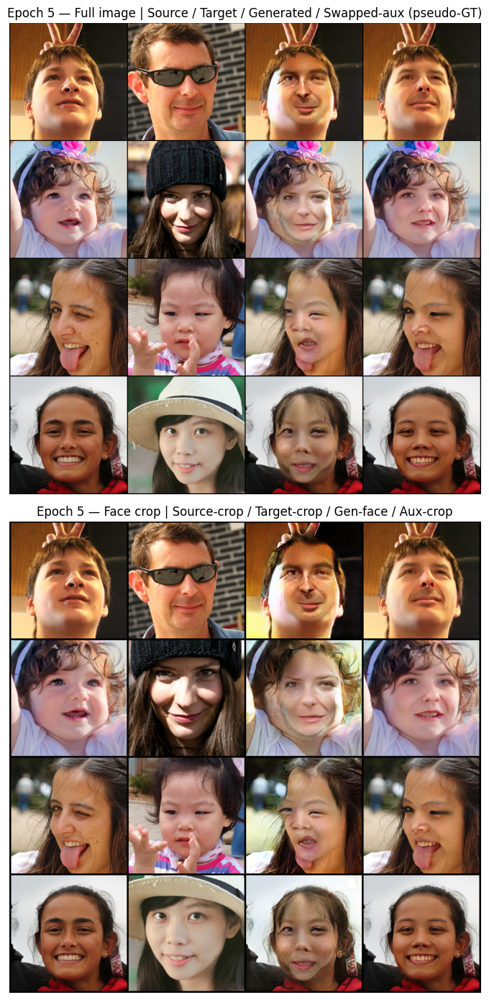

  [visuals saved: /kaggle/working/visuals/epoch_005.png]


Epoch 6/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 6 | step 0/9251 | global_step 99,252] [ETA: Calculating...] id=0.1293 rec=0.1663 adv=0.6855 aux=0.0805 boundary=0.0035 d=0.0587 | GPU0 alloc=0.44GB reserved=9.62GB | Host RAM=3.54GB
[epoch 6 | step 50/9251 | global_step 99,302] [ETA: 01:37:52] id=0.1639 rec=0.1392 adv=0.7431 aux=0.0718 boundary=0.0032 d=0.0596 | GPU0 alloc=0.44GB reserved=9.62GB | Host RAM=3.74GB
[epoch 6 | step 100/9251 | global_step 99,352] [ETA: 01:33:52] id=0.1497 rec=0.1511 adv=0.7351 aux=0.0729 boundary=0.0035 d=0.0498 | GPU0 alloc=0.44GB reserved=9.62GB | Host RAM=3.74GB
[epoch 6 | step 150/9251 | global_step 99,402] [ETA: 01:45:34] id=0.1349 rec=0.1546 adv=0.4783 aux=0.0725 boundary=0.0035 d=0.0858 | GPU0 alloc=0.44GB reserved=9.82GB | Host RAM=3.74GB
[epoch 6 | step 200/9251 | global_step 99,452] [ETA: 01:34:00] id=0.1314 rec=0.1458 adv=0.7021 aux=0.0726 boundary=0.0032 d=0.0434 | GPU0 alloc=0.44GB reserved=9.82GB | Host RAM=3.74GB
[epoch 6 | step 250/9251 | global_step 99,502] [ETA: 01:32:27] id=0.1456

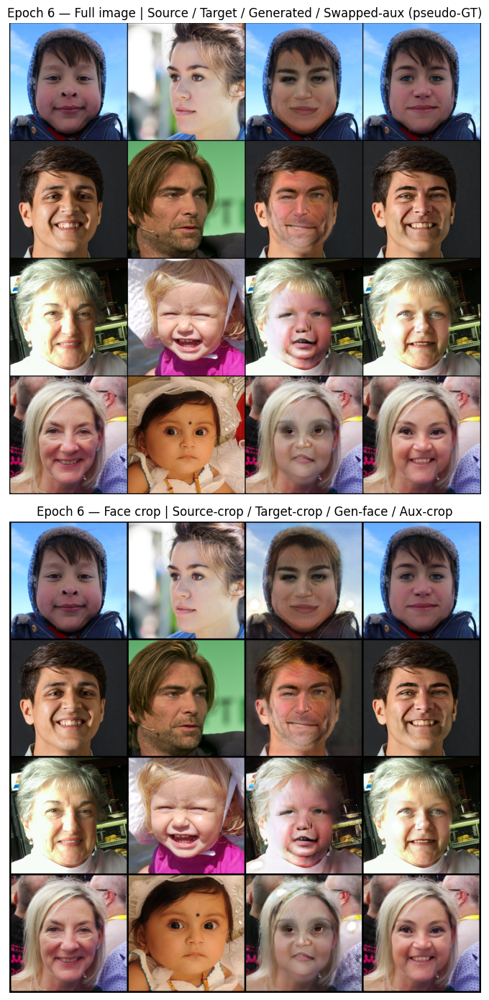

  [visuals saved: /kaggle/working/visuals/epoch_006.png]


Epoch 7/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 7 | step 0/9251 | global_step 108,503] [ETA: Calculating...] id=0.1197 rec=0.1289 adv=0.6809 aux=0.0611 boundary=0.0030 d=0.0743 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 7 | step 50/9251 | global_step 108,553] [ETA: 01:39:51] id=0.1367 rec=0.1440 adv=0.6186 aux=0.0675 boundary=0.0035 d=0.0700 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 7 | step 100/9251 | global_step 108,603] [ETA: 01:45:57] id=0.1228 rec=0.1466 adv=0.6778 aux=0.0683 boundary=0.0031 d=0.0510 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 7 | step 150/9251 | global_step 108,653] [ETA: 01:36:42] id=0.1348 rec=0.1370 adv=0.5160 aux=0.0683 boundary=0.0031 d=0.0873 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 7 | step 200/9251 | global_step 108,703] [ETA: 01:36:31] id=0.1159 rec=0.1414 adv=0.5809 aux=0.0684 boundary=0.0035 d=0.0736 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 7 | step 250/9251 | global_step 108,753] [ETA: 01:35:01] id=

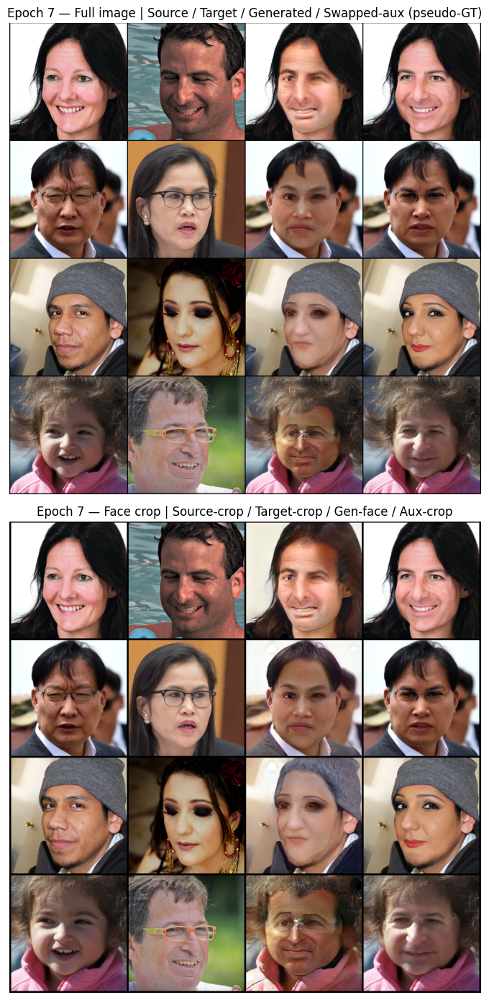

  [visuals saved: /kaggle/working/visuals/epoch_007.png]


Epoch 8/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 8 | step 0/9251 | global_step 117,754] [ETA: Calculating...] id=0.1312 rec=0.1537 adv=0.4137 aux=0.0733 boundary=0.0034 d=0.1049 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 8 | step 50/9251 | global_step 117,804] [ETA: 01:43:46] id=0.1114 rec=0.1400 adv=0.6742 aux=0.0668 boundary=0.0032 d=0.0597 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 8 | step 100/9251 | global_step 117,854] [ETA: 01:35:50] id=0.1088 rec=0.1383 adv=0.5249 aux=0.0673 boundary=0.0033 d=0.0876 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 8 | step 150/9251 | global_step 117,904] [ETA: 01:36:00] id=0.1372 rec=0.1348 adv=0.6742 aux=0.0680 boundary=0.0032 d=0.0667 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 8 | step 200/9251 | global_step 117,954] [ETA: 01:35:19] id=0.1267 rec=0.1309 adv=0.4055 aux=0.0688 boundary=0.0033 d=0.1374 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 8 | step 250/9251 | global_step 118,004] [ETA: 01:39:12] id=

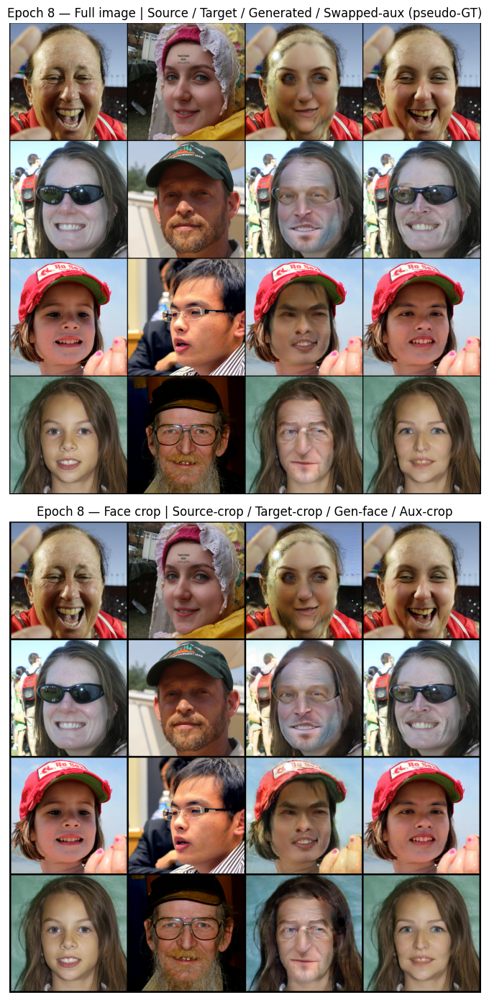

  [visuals saved: /kaggle/working/visuals/epoch_008.png]


Epoch 9/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 9 | step 0/9251 | global_step 127,005] [ETA: Calculating...] id=0.1118 rec=0.1240 adv=0.8775 aux=0.0590 boundary=0.0031 d=0.0579 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 9 | step 50/9251 | global_step 127,055] [ETA: 01:37:44] id=0.1275 rec=0.1518 adv=1.2057 aux=0.0658 boundary=0.0032 d=0.0382 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 9 | step 100/9251 | global_step 127,105] [ETA: 01:34:41] id=0.1320 rec=0.1363 adv=0.7034 aux=0.0682 boundary=0.0030 d=0.0416 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 9 | step 150/9251 | global_step 127,155] [ETA: 01:36:10] id=0.1313 rec=0.1375 adv=1.3541 aux=0.0675 boundary=0.0033 d=0.1412 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 9 | step 200/9251 | global_step 127,205] [ETA: 01:38:51] id=0.1293 rec=0.1437 adv=0.6282 aux=0.0667 boundary=0.0029 d=0.0605 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 9 | step 250/9251 | global_step 127,255] [ETA: 01:33:52] id=

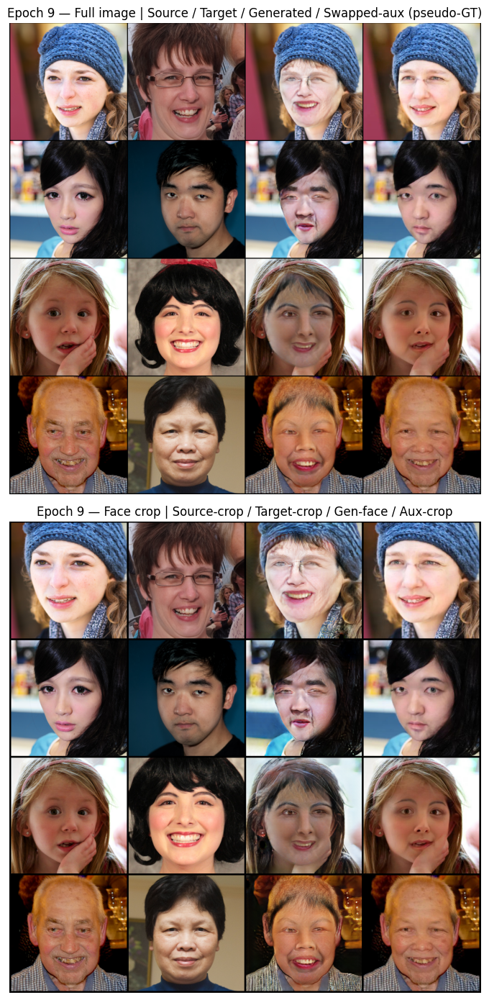

  [visuals saved: /kaggle/working/visuals/epoch_009.png]


Epoch 10/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 10 | step 0/9251 | global_step 136,256] [ETA: Calculating...] id=0.1355 rec=0.1263 adv=1.1595 aux=0.0602 boundary=0.0030 d=0.1321 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 10 | step 50/9251 | global_step 136,306] [ETA: 01:39:27] id=0.1153 rec=0.1406 adv=0.8068 aux=0.0640 boundary=0.0032 d=0.0791 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 10 | step 100/9251 | global_step 136,356] [ETA: 01:37:36] id=0.1193 rec=0.1287 adv=0.2880 aux=0.0649 boundary=0.0032 d=0.1704 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 10 | step 150/9251 | global_step 136,406] [ETA: 01:40:00] id=0.1383 rec=0.1470 adv=0.5849 aux=0.0648 boundary=0.0032 d=0.0711 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 10 | step 200/9251 | global_step 136,456] [ETA: 01:38:18] id=0.1300 rec=0.1554 adv=0.8656 aux=0.0649 boundary=0.0036 d=0.0786 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.60GB
[epoch 10 | step 250/9251 | global_step 136,506] [ETA: 01:37:1

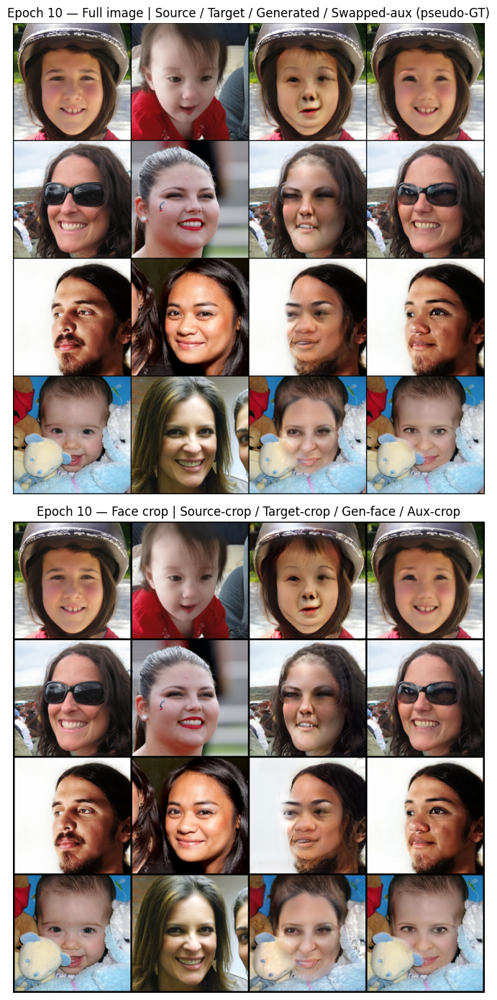

  [visuals saved: /kaggle/working/visuals/epoch_010.png]


Epoch 11/11:   0%|          | 0/9251 [00:00<?, ?step/s]

[epoch 11 | step 0/9251 | global_step 145,507] [ETA: Calculating...] id=0.1219 rec=0.1173 adv=0.7383 aux=0.0568 boundary=0.0029 d=0.0881 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 11 | step 50/9251 | global_step 145,557] [ETA: 01:39:39] id=0.1568 rec=0.1315 adv=0.5918 aux=0.0632 boundary=0.0034 d=0.0669 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 11 | step 100/9251 | global_step 145,607] [ETA: 01:40:19] id=0.1392 rec=0.1342 adv=0.3769 aux=0.0634 boundary=0.0032 d=0.1275 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 11 | step 150/9251 | global_step 145,657] [ETA: 01:37:30] id=0.1380 rec=0.1280 adv=0.7565 aux=0.0637 boundary=0.0030 d=0.0811 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 11 | step 200/9251 | global_step 145,707] [ETA: 01:35:48] id=0.1220 rec=0.1268 adv=0.5683 aux=0.0631 boundary=0.0029 d=0.0587 | GPU0 alloc=0.44GB reserved=9.41GB | Host RAM=3.56GB
[epoch 11 | step 250/9251 | global_step 145,757] [ETA: 01:34:5

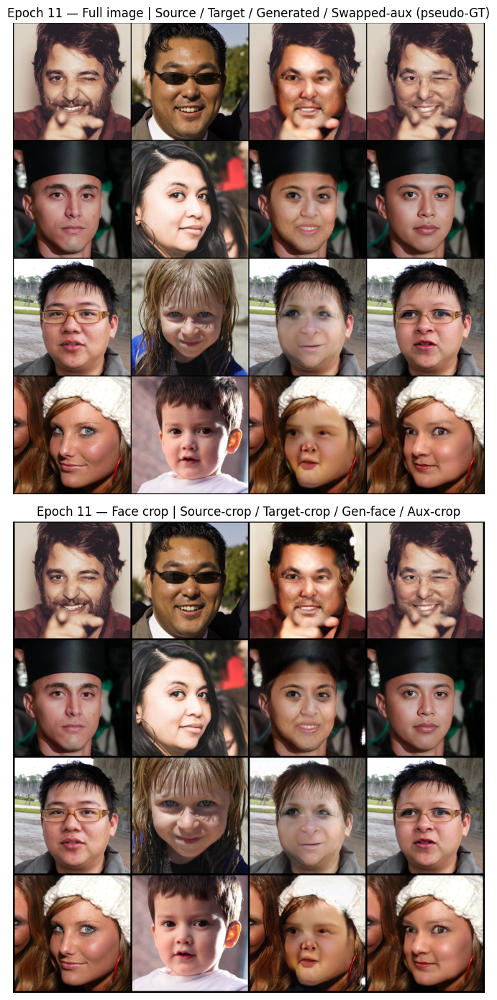

  [visuals saved: /kaggle/working/visuals/epoch_011.png]
Continuation complete. Final global_step = 154,757
Expected final global_step = 154,757


In [11]:
# ============================================================
# CELL 10 — Continuation training loop: 7 more epochs
# ============================================================

import time
import gc
import psutil
from tqdm.auto import tqdm

# Exactly 7 additional epochs after the checkpoint.
ADDITIONAL_EPOCHS = 7

LOG_EVERY = 50
CKPT_EVERY_STEPS = 10000
EMPTY_CACHE_EVERY = 200
GRAD_CLIP_NORM = 5.0


STEPS_PER_EPOCH = len(dataloader)

# The checkpoint already restored this
# Example: 90,000
print(f"Resuming from global_step = {global_step:,}")

# Determine how many complete epochs have already been processed
ORIGINAL_COMPLETED_EPOCHS = 5

START_EPOCH = ORIGINAL_COMPLETED_EPOCHS
END_EPOCH_EXCLUSIVE = START_EPOCH + ADDITIONAL_EPOCHS

_proc = psutil.Process(os.getpid())

def save_checkpoint(tag: str):
    torch.save({
        "generator": pipeline.generator.state_dict(),
        "discriminator": discriminator.state_dict(),
        "opt_g": opt_g.state_dict(),
        "opt_d": opt_d.state_dict(),
        "global_step": global_step,
    }, os.path.join(CHECKPOINT_DIR, f"ckpt_{tag}.pt"))
    print(f"  [checkpoint saved: ckpt_{tag}.pt]")

print("=" * 80)
print(
    f"RESUMED TRAINING: epochs {START_EPOCH}–{END_EPOCH_EXCLUSIVE - 1} "
    f"({ADDITIONAL_EPOCHS} additional epochs)"
)
print(f"Starting global step: {global_step:,}")
print(f"Expected final global step: {global_step + ADDITIONAL_EPOCHS * len(dataloader):,}")
print("=" * 80)

for epoch in range(START_EPOCH, END_EPOCH_EXCLUSIVE):
    epoch_start = time.time()

    running = {
        "id": 0.0,
        "rec": 0.0,
        "adv": 0.0,
        "aux": 0.0,
        "boundary": 0.0,
        "d": 0.0,
    }
    n_batches = 0

    pbar = tqdm(
        enumerate(dataloader),
        total=len(dataloader),
        desc=f"Epoch {epoch}/{END_EPOCH_EXCLUSIVE - 1}",
        unit="step",
        dynamic_ncols=True,
    )

    for step, batch in pbar:
        source_img = batch["source"].to(device, non_blocking=True)
        target_img = batch["target"].to(device, non_blocking=True)

        swapped_aux = batch.get("swapped_aux")
        if swapped_aux is not None:
            swapped_aux = swapped_aux.to(device, non_blocking=True)

        target_face_crop = get_target_face_crop(target_img)

        # -------------------------
        # Generator forward + loss
        # -------------------------
        with torch.amp.autocast("cuda"):
            composite, mask, source_crop, gen_face_01, target_crop = pipeline(
                source_img,
                target_face_crop
            )

            gen_face = gen_face_01 * 2 - 1
            target_crop_n = target_crop * 2 - 1
            source_crop_n = source_crop * 2 - 1

            l_id = identity_loss_fn(gen_face, target_crop_n)
            l_rec = F.l1_loss(gen_face, source_crop_n)

            pred_fake = discriminator(gen_face)
            l_adv = F.mse_loss(
                pred_fake,
                torch.ones_like(pred_fake)
            )

            l_boundary = boundary_consistency_loss(
                composite,
                source_img,
                mask
            )

            if swapped_aux is not None:
                with torch.no_grad():
                    aux_mask = pipeline.mask_extractor(source_img)
                    aux_boxes = mask_to_bbox(aux_mask)

                aux_crop = crop_faces(
                    swapped_aux,
                    aux_boxes,
                    CROP_SIZE
                )
                l_aux = F.l1_loss(gen_face_01, aux_crop)
            else:
                l_aux = torch.tensor(0.0, device=device)

            g_loss = (
                LAMBDA_ID * l_id
                + LAMBDA_REC * l_rec
                + LAMBDA_ADV * l_adv
                + LAMBDA_AUX * l_aux
                + LAMBDA_BOUNDARY * l_boundary
            )

        opt_g.zero_grad(set_to_none=True)

        scaler_g.scale(g_loss).backward()

        scaler_g.unscale_(opt_g)

        torch.nn.utils.clip_grad_norm_(
            filter(
                lambda p: p.requires_grad,
                pipeline.parameters()
            ),
            GRAD_CLIP_NORM
        )

        scaler_g.step(opt_g)
        scaler_g.update()

        # -------------------------
        # Discriminator
        # -------------------------
        with torch.amp.autocast("cuda"):
            real_crop = source_crop_n.detach()
            fake_crop = gen_face.detach()

            pred_real = discriminator(real_crop)
            pred_fake_d = discriminator(fake_crop)

            d_loss = 0.5 * (
                F.mse_loss(
                    pred_real,
                    torch.ones_like(pred_real)
                )
                +
                F.mse_loss(
                    pred_fake_d,
                    torch.zeros_like(pred_fake_d)
                )
            )

        opt_d.zero_grad(set_to_none=True)

        scaler_d.scale(d_loss).backward()
        scaler_d.step(opt_d)
        scaler_d.update()

        # -------------------------
        # Metrics
        # -------------------------
        id_val = l_id.item()
        rec_val = l_rec.item()
        adv_val = l_adv.item()
        aux_val = l_aux.item() if torch.is_tensor(l_aux) else l_aux
        boundary_val = l_boundary.item()
        d_val = d_loss.item()

        running["id"] += id_val
        running["rec"] += rec_val
        running["adv"] += adv_val
        running["aux"] += aux_val
        running["boundary"] += boundary_val
        running["d"] += d_val

        n_batches += 1
        global_step += 1

        # tqdm's own display includes elapsed/rate/ETA.
        pbar.set_postfix({
            "step": global_step,
            "id": f"{id_val:.3f}",
            "rec": f"{rec_val:.3f}",
            "adv": f"{adv_val:.3f}",
            "d": f"{d_val:.3f}",
        })

        # Explicit ETA for notebook logs.
        format_dict = pbar.format_dict
        rate = format_dict.get("rate")

        if rate and rate > 0:
            remaining_sec = (
                format_dict["total"] - format_dict["n"]
            ) / rate
            eta_str = time.strftime(
                "%H:%M:%S",
                time.gmtime(remaining_sec)
            )
        else:
            eta_str = "Calculating..."

        # Free references before periodic cache cleanup.
        del (
            composite,
            mask,
            source_crop,
            gen_face_01,
            target_crop,
            gen_face,
            target_crop_n,
            source_crop_n,
            pred_fake,
            pred_real,
            pred_fake_d,
            source_img,
            target_img,
            target_face_crop,
            batch,
            l_id,
            l_rec,
            l_adv,
            l_boundary,
            l_aux,
            g_loss,
            d_loss,
        )

        if swapped_aux is not None:
            del swapped_aux, aux_crop, aux_mask, aux_boxes

        if global_step % EMPTY_CACHE_EVERY == 0:
            gc.collect()
            torch.cuda.empty_cache()

        if step % LOG_EVERY == 0:
            mem_alloc = torch.cuda.memory_allocated(0) / 1e9
            mem_reserved = torch.cuda.memory_reserved(0) / 1e9
            host_ram_gb = _proc.memory_info().rss / 1e9

            pbar.write(
                f"[epoch {epoch} | step {step}/{len(dataloader)} | "
                f"global_step {global_step:,}] "
                f"[ETA: {eta_str}] "
                f"id={id_val:.4f} "
                f"rec={rec_val:.4f} "
                f"adv={adv_val:.4f} "
                f"aux={running['aux']/n_batches:.4f} "
                f"boundary={boundary_val:.4f} "
                f"d={d_val:.4f} | "
                f"GPU0 alloc={mem_alloc:.2f}GB "
                f"reserved={mem_reserved:.2f}GB | "
                f"Host RAM={host_ram_gb:.2f}GB"
            )

        if global_step % CKPT_EVERY_STEPS == 0:
            save_checkpoint(f"step{global_step}")

    pbar.close()

    epoch_time = time.time() - epoch_start

    print(
        f"=== Epoch {epoch} done in {epoch_time/60:.1f} min | "
        f"avg id={running['id']/n_batches:.4f} "
        f"rec={running['rec']/n_batches:.4f} "
        f"adv={running['adv']/n_batches:.4f} "
        f"d={running['d']/n_batches:.4f} | "
        f"global_step={global_step:,} ==="
    )

    # Same per-epoch checkpoint + visualizations as the original notebook.
    save_checkpoint(f"epoch{epoch}")
    save_epoch_visuals(
        epoch,
        dataloader,
        pipeline
    )

    gc.collect()
    torch.cuda.empty_cache()

print("=" * 80)
print(
    f"Continuation complete. Final global_step = {global_step:,}"
)
print(
    f"Expected final global_step = "
    f"{90_000 + ADDITIONAL_EPOCHS * len(dataloader):,}"
)
print("=" * 80)


After the 7-epoch continuation, the notebook produces the same per-epoch visualizations for epochs 5 through 11 and saves the final continuation checkpoint at global step 126,000 when the DataLoader remains 18,000 batches/epoch.